# 01 · Exploratory Data Analysis

**Goal:** understand the Spanish electricity market data before building any model.

Questions we want to answer:
1. How does the electricity price behave over time? Any trend or regime change?
2. Are there daily, weekly and yearly patterns (seasonality)?
3. Which energy sources and weather variables move together with the price?
4. How good is the official day-ahead price forecast that comes with the dataset? (This is the benchmark our model has to beat.)

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd

from src.data.load import load_dataset
from src.plot_style import PALETTE, TEXT_SECONDARY, apply_style

apply_style()
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

## 1. Load the data

`load_dataset()` (in `src/data/load.py`) already handles the cleaning:

- timestamps are converted from mixed UTC offsets to Madrid local time
- 8 columns that are completely empty or always zero are dropped
- weather: duplicate rows removed, Kelvin → °C, impossible pressure/wind values removed
- weather is reshaped to one column per city and joined to the energy data

In [2]:
df = load_dataset()
print(f"{df.shape[0]:,} hourly rows × {df.shape[1]} columns")
print(f"From {df.index.min():%Y-%m-%d} to {df.index.max():%Y-%m-%d}")
df[["price_actual", "price_day_ahead", "total_load_actual", "generation_wind_onshore", "generation_solar", "madrid_temp"]].describe().round(1)

35,064 hourly rows × 55 columns
From 2015-01-01 to 2018-12-31


,price_actual,price_day_ahead,total_load_actual,generation_wind_onshore,generation_solar,madrid_temp
count,35064.0,35064.0,35062.0,35064.0,35064.0,35064.0
mean,57.9,49.9,28698.0,5465.0,1432.8,15.1
std,14.2,14.6,4575.8,3213.6,1680.0,9.3
min,9.3,2.1,18041.0,0.0,0.0,-9.0
25%,49.3,41.5,24807.0,2933.0,71.0,8.0
50%,58.0,50.5,28901.5,4849.5,616.0,13.8
75%,68.0,60.5,32194.0,7399.5,2579.0,21.8
max,116.8,102.0,41015.0,17436.0,5792.0,40.2


In [3]:
missing = df.isna().sum()
missing[missing > 0]

total_load_actual      2
barcelona_pressure    13
dtype: int64

Only a handful of values remain missing (longer gaps that we did not want to invent values for). We will handle them in the feature-engineering step.

## 2. Price over time

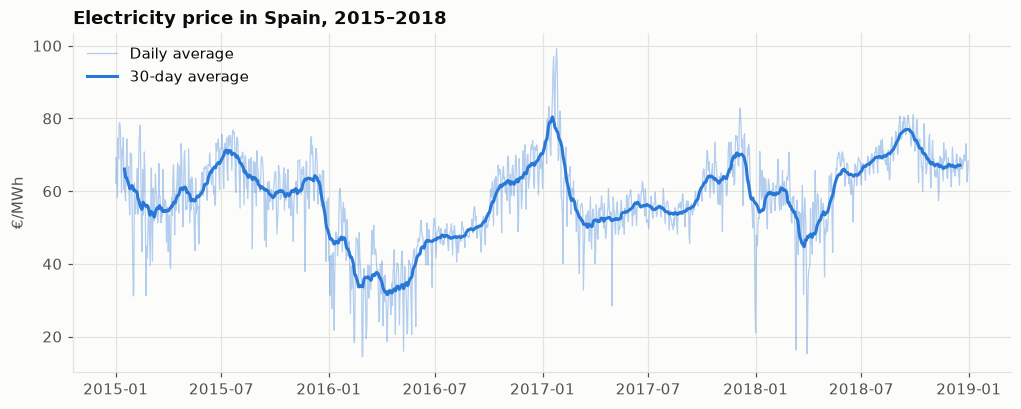

In [4]:
daily = df["price_actual"].resample("D").mean()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(daily.index, daily, color=PALETTE[0], linewidth=0.8, alpha=0.35, label="Daily average")
ax.plot(daily.index, daily.rolling(30, center=True).mean(), color=PALETTE[0], linewidth=2, label="30-day average")
ax.set_title("Electricity price in Spain, 2015–2018")
ax.set_ylabel("€/MWh")
ax.legend(loc="upper left")
fig.savefig(FIG_DIR / "price_over_time.png")
plt.show()

In [5]:
yearly = df["price_actual"].groupby(df.index.year).agg(["mean", "std", "min", "max"]).round(1)
yearly

,mean,std,min,max
time,,,,
2015,61.4,12.3,13.5,102.6
2016,47.4,14.2,9.3,86.4
2017,59.3,12.3,12.0,116.8
2018,63.4,12.2,10.7,91.9


## 3. Distribution of hourly prices

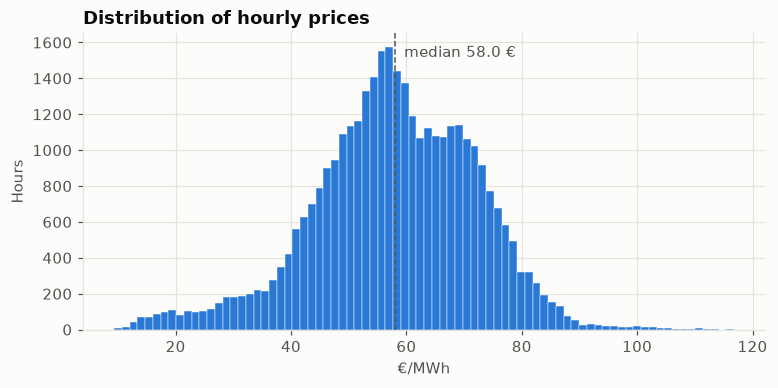

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(df["price_actual"], bins=80, color=PALETTE[0], edgecolor="white", linewidth=0.3)
ax.axvline(df["price_actual"].median(), color=TEXT_SECONDARY, linestyle="--", linewidth=1)
ax.annotate(f"median {df['price_actual'].median():.1f} €", xy=(df["price_actual"].median(), ax.get_ylim()[1] * 0.92),
            xytext=(6, 0), textcoords="offset points", color=TEXT_SECONDARY)
ax.set_title("Distribution of hourly prices")
ax.set_xlabel("€/MWh")
ax.set_ylabel("Hours")
plt.show()

## 4. Seasonality

Electricity demand follows human routines, so we expect clear patterns by hour of day, day of week and month.

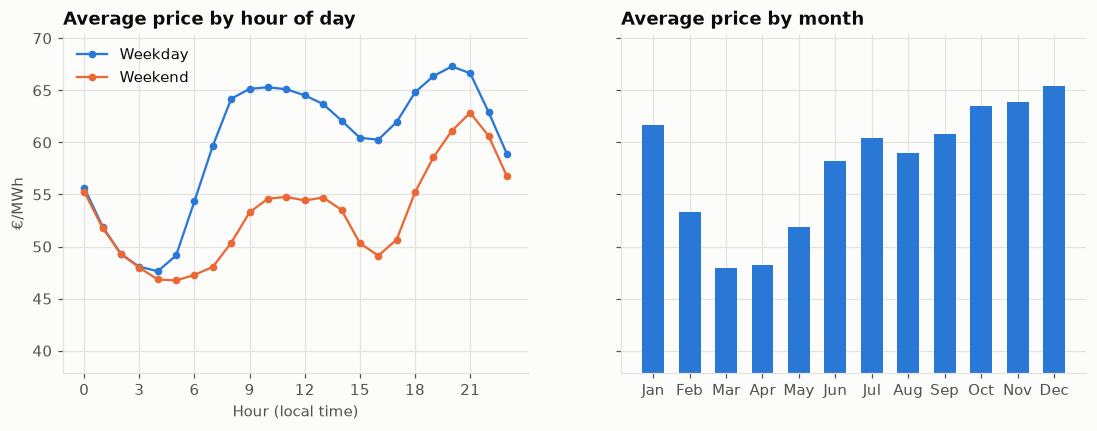

In [7]:
tmp = df[["price_actual"]].copy()
tmp["hour"] = tmp.index.hour
tmp["is_weekend"] = tmp.index.dayofweek >= 5
tmp["month"] = tmp.index.month

by_hour = tmp.groupby(["hour", "is_weekend"])["price_actual"].mean().unstack()
by_month = tmp.groupby("month")["price_actual"].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

axes[0].plot(by_hour.index, by_hour[False], color=PALETTE[0], marker="o", markersize=4, label="Weekday")
axes[0].plot(by_hour.index, by_hour[True], color=PALETTE[1], marker="o", markersize=4, label="Weekend")
axes[0].set_title("Average price by hour of day")
axes[0].set_xlabel("Hour (local time)")
axes[0].set_ylabel("€/MWh")
axes[0].set_xticks(range(0, 24, 3))
axes[0].legend()

month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
axes[1].bar(month_names, by_month.values, color=PALETTE[0], width=0.6)
axes[1].set_title("Average price by month")
axes[1].set_ylim(by_month.min() - 10, by_month.max() + 5)

fig.savefig(FIG_DIR / "seasonality.png")
plt.show()

## 5. Generation mix

Which sources produce Spain's electricity? Prices are set by the most expensive plant needed to meet demand,
so the share of cheap (wind, solar, nuclear, hydro) vs. expensive (gas, coal) generation matters a lot.

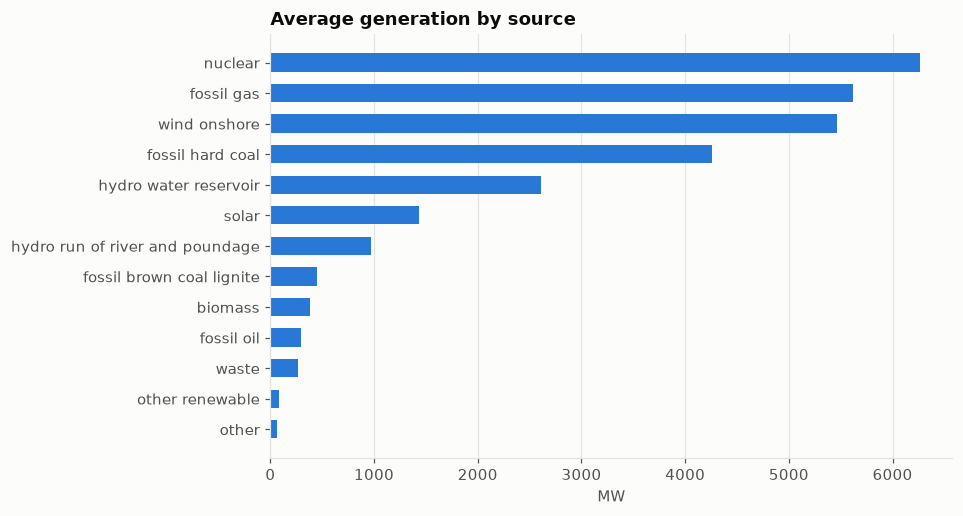

In [8]:
gen_cols = [c for c in df.columns if c.startswith("generation_") and c != "generation_hydro_pumped_storage_consumption"]
gen_mean = df[gen_cols].mean().sort_values()
gen_mean.index = gen_mean.index.str.replace("generation_", "").str.replace("_", " ")

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(gen_mean.index, gen_mean.values, color=PALETTE[0], height=0.6)
ax.set_title("Average generation by source")
ax.set_xlabel("MW")
ax.grid(axis="y", visible=False)
plt.show()

## 6. What moves with the price?

Correlation is not causation, but it tells us which variables are promising features.

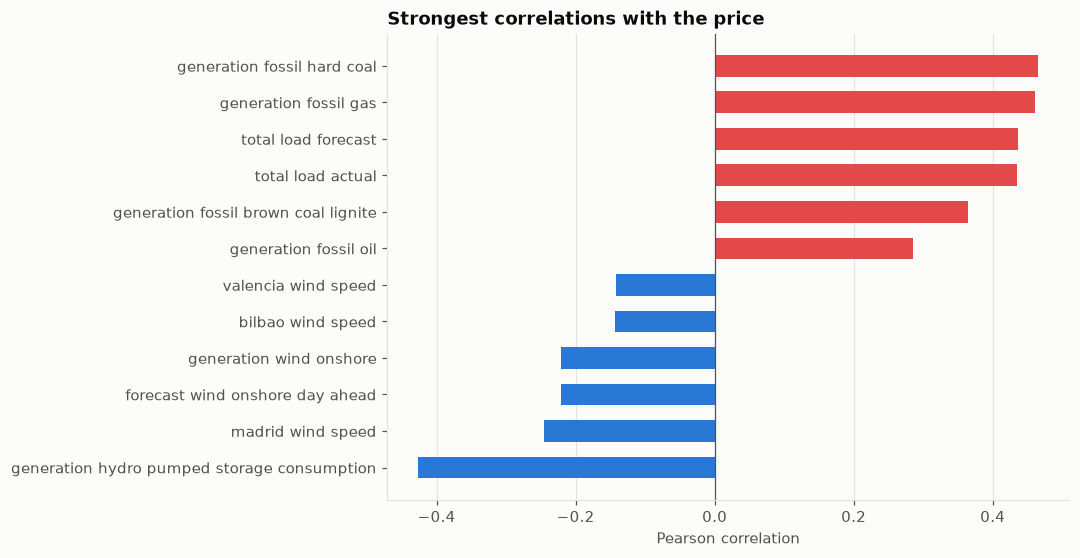

In [9]:
corr = df.corr(numeric_only=True)["price_actual"].drop(["price_actual", "price_day_ahead"])
top = pd.concat([corr.nsmallest(6), corr.nlargest(6)]).sort_values()
top.index = top.index.str.replace("_", " ")

colors = [PALETTE[0] if v < 0 else PALETTE[7] for v in top.values]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top.index, top.values, color=colors, height=0.6)
ax.axvline(0, color=TEXT_SECONDARY, linewidth=0.8)
ax.set_title("Strongest correlations with the price")
ax.set_xlabel("Pearson correlation")
ax.grid(axis="y", visible=False)
fig.savefig(FIG_DIR / "price_correlations.png")
plt.show()

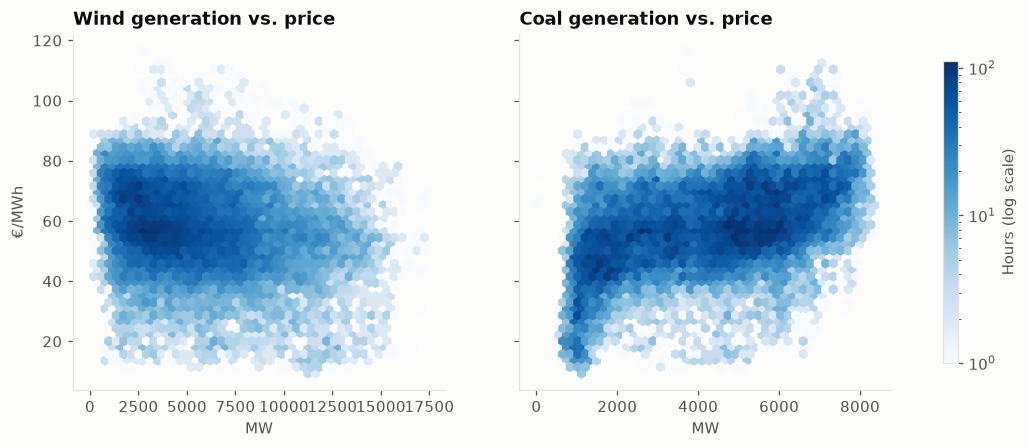

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, col, title in [
    (axes[0], "generation_wind_onshore", "Wind generation vs. price"),
    (axes[1], "generation_fossil_hard_coal", "Coal generation vs. price"),
]:
    hb = ax.hexbin(df[col], df["price_actual"], gridsize=45, cmap="Blues", mincnt=1, bins="log")
    ax.set_title(title)
    ax.set_xlabel("MW")
    ax.grid(False)
axes[0].set_ylabel("€/MWh")
fig.colorbar(hb, ax=axes, label="Hours (log scale)", shrink=0.85)
fig.savefig(FIG_DIR / "wind_coal_vs_price.png")
plt.show()

## 7. The benchmark: official day-ahead forecast

The dataset includes `price_day_ahead`, the price forecast published by the grid operator one day in advance.
Any model we build must beat this to be useful.

In [11]:
err = df["price_actual"] - df["price_day_ahead"]
benchmark = pd.Series({
    "MAE (€/MWh)": err.abs().mean(),
    "RMSE (€/MWh)": np.sqrt((err ** 2).mean()),
    "Mean bias (€/MWh)": err.mean(),
}).round(2)
benchmark

MAE (€/MWh)          10.49
RMSE (€/MWh)         13.25
Mean bias (€/MWh)     8.01
dtype: float64

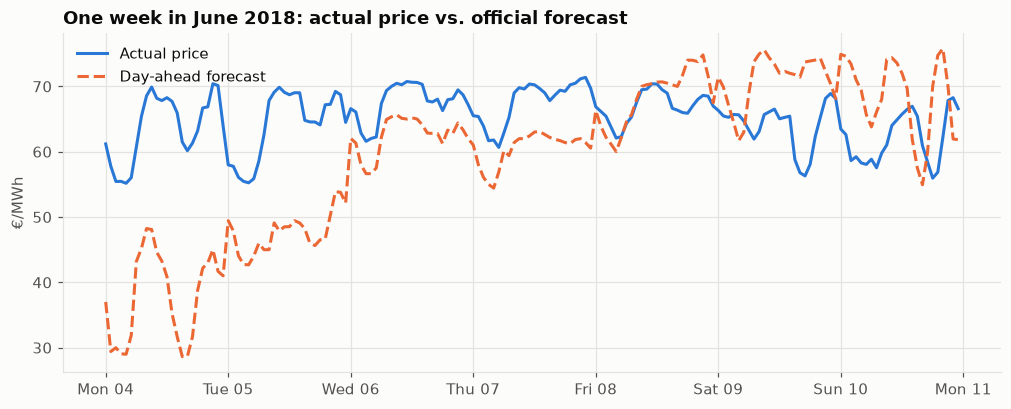

In [12]:
week = df.loc["2018-06-04":"2018-06-10", ["price_actual", "price_day_ahead"]]

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(week.index, week["price_actual"], color=PALETTE[0], linewidth=2, label="Actual price")
ax.plot(week.index, week["price_day_ahead"], color=PALETTE[1], linewidth=2, linestyle="--", label="Day-ahead forecast")
ax.set_title("One week in June 2018: actual price vs. official forecast")
ax.set_ylabel("€/MWh")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%a %d", tz=week.index.tz))
ax.legend(loc="upper left")
fig.savefig(FIG_DIR / "benchmark_week.png")
plt.show()

## Key findings

1. **Prices are volatile and regime-dependent.** Hourly prices range from 9 to 117 €/MWh (mean ≈ 58). 2016 was much cheaper (≈ 47 €) than other years, and January 2017 shows a sharp spike that coincides with the European cold spell.
2. **Strong seasonality.** Weekdays have two daily peaks (morning 9–12h and evening 19–21h); weekends are up to ~10 € cheaper during the day. Spring (March–April) is the cheapest season, winter the most expensive.
3. **The generation mix drives the price.** Coal, gas and demand move *with* the price; wind moves *against* it: windy hours are cheaper. Hydro pumped-storage consumption is negatively correlated because operators pump water *when* power is cheap. It is a consequence of the price, not a cause.
4. **The official forecast has a clear weakness.** The day-ahead forecast has an MAE of **10.5 €/MWh** and systematically underestimates the actual price by **≈ 8 €** on average. This is the benchmark our model has to beat.

### Implications for modelling

- Actual generation values are only known *after* the hour, so a real day-ahead model cannot use them directly. We will use **forecasts** (load, wind, solar) and **lagged** values (e.g. price 24h and 168h ago) instead, to avoid data leakage.
- Calendar features (hour, weekday, month, holidays) will be essential.
- We must split train/test **by time**, not randomly, since prices drift between years.

In [13]:
df.to_parquet("../data/processed/energy_weather.parquet")